# EARTHSC 5201: Homework 1
## Rory Levinson

### Question 1
#### Describe the differences between source, path, and site terms? What are common examples for each of these terms? Explain how certain site terms will alter your observed ground motions.
##### In general, source, path, and site conditions shape every seismic recording.
##### **Source** terms involve what generates a seismic wave, including natural events such as earthquakes, volcanoes, and landslides, as well as human-made sources like traffic and certain explosions. Natural events have uncertainty in their origin time, location, and size, while controlled sources reduce uncertainty and provide a clearer view of path and site terms. Each type of source term has a distinct duration, frequency content, and envelope shape, allowing researchers to discriminate between them.
##### **Path** terms involve what occurs along the way as a seismic wave travels from source to site. As these waves travel through the Earth, they sample the composition of the materials they cross, which affects their measurements. The primary observable path terms are P- and S-wave velocities, which are affected by materials' elastic moduli and densities. These velocities and other terms allow researchers to uncover material properties in the subsurface using ray theory, tomography, and reflection seismology.
##### **Site** terms involve the local effects of seismic waves and the specific classifications of sites. Localized effects near a seismometer are captured and assist in earthquake engineering, early warning, and rapid response. Common metrics include VS30 (shear-wave velocity in the upper 30 m) and Z1.0 (depth to 1 km/s shear-wave speed). Certain site terms will alter your observed ground motions, so corrections need to be made to uncover accurate seismic data. For example, hard rock will act very differently from soft clay when exposed to a seismic wave, and may exhibit much higher VS30 (1500 m/s) than clay's VS30 (<180 m/s). Thus, seismometer data must be corrected and normalized for the material at the site in order for an accurate measurement.

### Question 2

#### Find a vertical component velocity seismometer in an urban area versus a rural area. Compute and plot the probabilistic power spectrum for a day of data. Label the microseism band on the plots. Which of the two stations has less noise and why?

##### Setup:

In [1]:
!mamba install obspy

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, obspy
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.074 seconds
  Name                Version    Build                Channel
---------------------------------------------------------------------------
+ annotated-doc       0.0.5      pyhcf101f3_0         conda-forge
+ backports           1.0        pyhd8ed1ab_5         conda-forge
+ backports.tarfile   1.2.0      pyhcf101f3_2         conda-forge
+ brotli-python       1.2.0      py313ha26e73d_2      emscripten-forge-4x
+ certifi             2026.7.22  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1      pyhd8ed1ab_0         conda-forge
+ colorama            0.4.6      pyhd8ed1ab_1         conda-forge
+ idna                3.19       pyhcf101f3_0         conda-forge
+ jaraco.context      6.1.2      pyhcf101f3_0         conda-forge
+ jaraco.functools    4.6.0      pyhcf101f3_0         conda

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from obspy.clients.fdsn import Client

plt.rcParams["figure.figsize"] = (10,4)

##### Connect to EarthScope:

In [3]:
client = Client("https://service.earthscope.org", _discover_services=False)

##### Searching Geographically:

In [4]:
inventory_box = client.get_stations(
    network="CI",
    channel="HHZ",
    starttime=UTCDateTime("2024-12-01"),
    latitude=34.0, longitude=-118.0,
    maxradius=10,
    level="station",
)
print(inventory_box)

Inventory created at 2026-09-21T14:27:04.254800Z
	Created by: EarthScope WEB SERVICE: fdsnws-station | version: 1.1.57
		    https://service.earthscope.org/fdsnws/station/1/query?starttime=202...
	Sending institution: EarthScope (EarthScope)
	Contains:
		Networks (1):
			CI
		Stations (332):
			CI.ABL (Mount Abel)
			CI.ACP (Agua Caliente County Park)
			CI.ADO (Adelanto Receiving)
			CI.AGM (American Girl Mine)
			CI.ALP (Antelope)
			CI.ANG (Aguanga)
			CI.ARV (Arvin)
			CI.AVM (Alvord Mountain)
			CI.BAC (Bachelor Mountain)
			CI.BAI (Bailey)
			CI.BAK (Calstate Bakersfield)
			CI.BAR (Barrett)
			CI.BAW (Barstow)
			CI.BBR (Big Bear Solar Observatory)
			CI.BBS (Beaumont Base)
			CI.BC3 (Big Chuckawalla Mtns)
			CI.BCH (Branch Mtn)
			CI.BCW (Bitter Creek Wildlife)
			CI.BEL (Belle Mountain Joshua Tree)
			CI.BFS (Mt. Baldy Ranger Station)
			CI.BHP (Baldwin Hills)
			CI.BLA2 (Black Rock Canyon Campground 2)
			CI.BLC (Black Canyon)
			CI.BLY (Blythe)
			CI.BOM (Bombay Beach)
			CI

##### Urban (Los Angeles, CA):

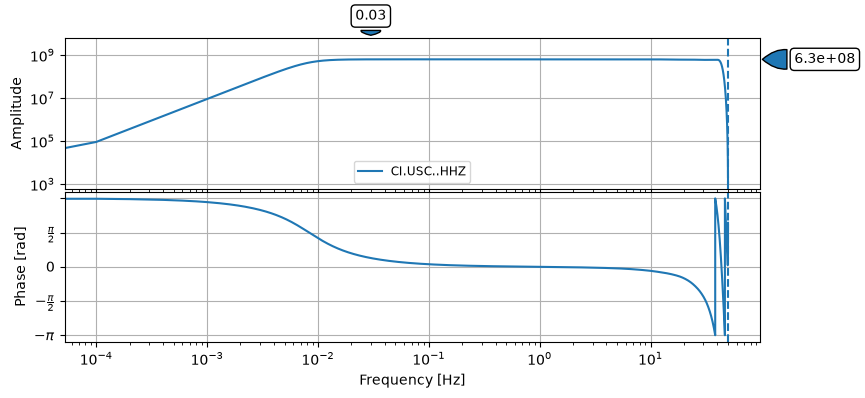

In [5]:
inv_resp_u = client.get_stations(
    network="CI", station="USC", channel="HHZ",
    starttime=UTCDateTime("2025-09-22"), endtime=UTCDateTime("2025-09-23"),
    level="response",
)

inv_resp_u.plot_response(min_freq=1e-4);

##### Rural (Dulzura, CA):

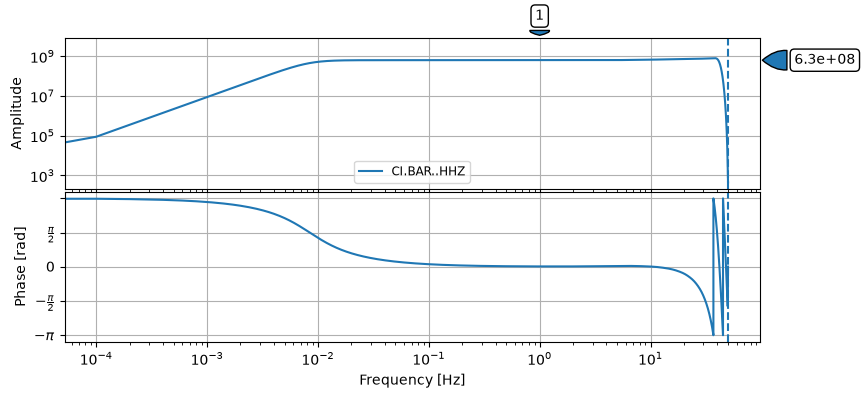

In [6]:
inv_resp_r = client.get_stations(
    network="CI", station="BAR", channel="HHZ",
    starttime=UTCDateTime("2025-09-22"), endtime=UTCDateTime("2025-09-23"),
    level="response",
)

inv_resp_r.plot_response(min_freq=1e-4);

##### Probabilistic Power Spectrums:

###### Urban:

In [7]:
net = "CI"
sta_u = "USC"
loc = ""
chan_Z = "HHZ"

In [8]:
event_time = UTCDateTime("2025-09-22T00:01:01")
starttime = event_time
endtime = event_time + 86400   # 1 day of data

my_stream_u = client.get_waveforms(net, sta_u, loc, chan_Z, starttime, endtime, attach_response=True)
print(my_stream_u)

/tmp/xpython_42/3148865438.py:5: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  my_stream_u = client.get_waveforms(net, sta_u, loc, chan_Z, starttime, endtime, attach_response=True)


1 Trace(s) in Stream:
CI.USC..HHZ | 2025-09-22T00:01:01.008393Z - 2025-09-23T00:01:00.998393Z | 100.0 Hz, 8640000 samples


In [9]:
from obspy import read, read_inventory
from obspy.io.xseed import Parser
from obspy.signal import PPSD

tr_u = my_stream_u[0]

ppsd_u = PPSD(tr_u.stats, metadata=inv_resp_u)
ppsd_u.add(tr_u)

print("Number of PSD segments:", len(ppsd_u.times_processed))

Number of PSD segments: 47


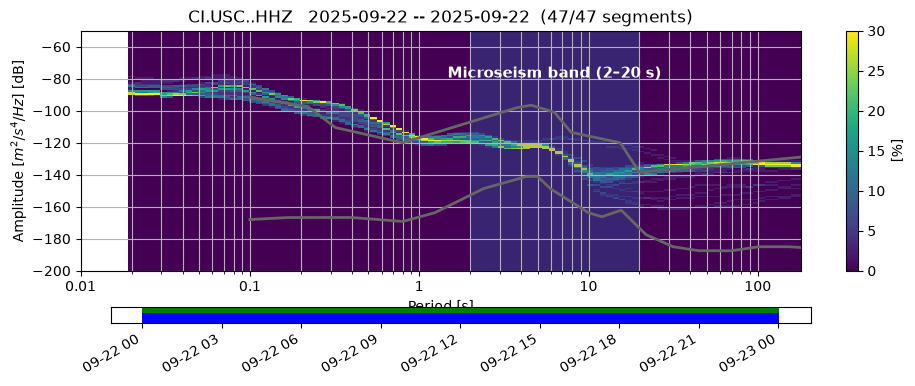

In [10]:
import matplotlib.pyplot as plt

plt.close("all")
fig = ppsd_u.plot(show=False)
ax = fig.axes[0]
ax.axvspan(2, 20, alpha=0.30)
ax.text(6.3, -72, "Microseism band (2–20 s)", color="white", ha="center", va="top", fontsize=11, fontweight="bold")
plt.show()

###### Rural:

In [11]:
net = "CI"
sta_r = "BAR"
loc = ""
chan_Z = "HHZ"

In [12]:
event_time = UTCDateTime("2025-09-22T00:01:01")
starttime = event_time
endtime = event_time + 86400   # 1 day of data

my_stream_r = client.get_waveforms(net, sta_r, loc, chan_Z, starttime, endtime, attach_response=True)
print(my_stream_r)

/tmp/xpython_42/1379426808.py:5: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  my_stream_r = client.get_waveforms(net, sta_r, loc, chan_Z, starttime, endtime, attach_response=True)


1 Trace(s) in Stream:
CI.BAR..HHZ | 2025-09-22T00:01:01.000470Z - 2025-09-23T00:01:00.990470Z | 100.0 Hz, 8640000 samples


In [13]:
from obspy import read, read_inventory
from obspy.io.xseed import Parser
from obspy.signal import PPSD

tr_r = my_stream_r[0]

ppsd_r = PPSD(tr_r.stats, metadata=inv_resp_r)
ppsd_r.add(tr_r)

print("Number of PSD segments:", len(ppsd_r.times_processed))

Number of PSD segments: 47


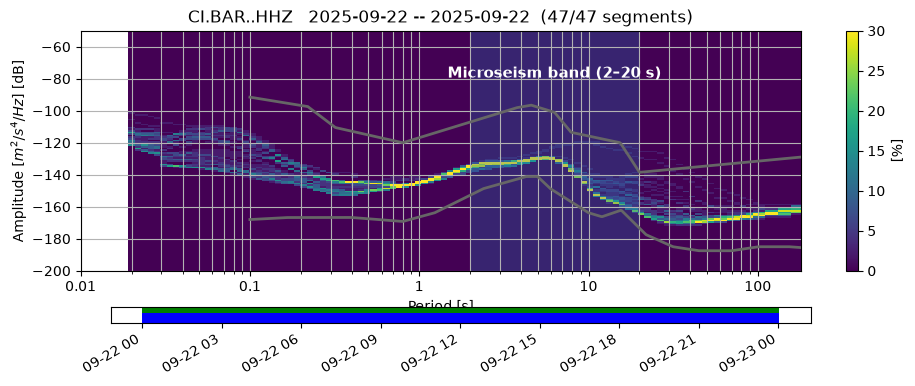

In [14]:
import matplotlib.pyplot as plt

plt.close("all")
fig = ppsd_r.plot(show=False)
ax = fig.axes[0]
ax.axvspan(2, 20, alpha=0.30)
ax.text(6.3, -72, "Microseism band (2–20 s)", color="white", ha="center", va="top", fontsize=11, fontweight="bold")
plt.show()

##### The station that has less noise is the rural station at Barrett Dam in Dulzura, California (CI.BAR). Within the microseism band (approximately 2-20 seconds period), the urban station (CI.USC) in Los Angeles has noise levels between ~-140 and ~-115 dB, while the rural station has noise levels between ~-160 and ~-130 dB. In general, the urban station has a higher (less negative) amount of noise than in the rural area evidenced by its higher dB range. The most likely reason for this difference is the higher degree of anthropogenic noise due to traffic, machinery, construction, etc. This noise increases the measured seismic noise in urban settings, while the rural station is mostly isolated from these sources.

### Question 3a

#### The Sumatra region of Indonesia has experienced 10 M7.5+ earthquakes since 2000. For 4 of the earthquakes, plot the vertical component velocity seismograms (either BHZ or HHZ) at the same station for 1 hour after the origin time. Comment on apparent differences between the seismograms. From the apparent P-wave arrivals, make an estimate of the average P-wave velocity. Next, plot the power spectral densities of these waveforms and comment on any differences you see. Use the USGS earthquake catalog to find information about these earthquakes (https://earthquake.usgs.gov/earthquakes/map).

##### M 9.1 - 2004 Sumatra - Andaman Islands Earthquake

In [15]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

event1 = client_events.get_events(
    starttime=UTCDateTime("2004-12-25"),
    endtime=UTCDateTime("2004-12-27"),
    minmagnitude=9.0,
    maxmagnitude=9.2,
)
print(event1)

1 Event(s) in Catalog:
2004-12-26T00:58:53.450000Z |  +3.295,  +95.982 | 9.1  mw | manual


In [16]:
eventa = event1[0]
origina = eventa.preferred_origin() or eventa.origins[0]
magnitudea = eventa.preferred_magnitude() or eventa.magnitudes[0]

print(f"{origina.time}  M{magnitudea.mag:.1f}  "
      f"lat={origina.latitude:.2f}, lon={origina.longitude:.2f}, depth={origina.depth/1000:.1f} km")

2004-12-26T00:58:53.450000Z  M9.1  lat=3.29, lon=95.98, depth=30.0 km


In [17]:
t0a = origina.time
sta = client.get_waveforms(
    network="PS", station="PSI", location="", channel="BHZ",
    starttime=t0a, endtime=t0a + 3600,
)

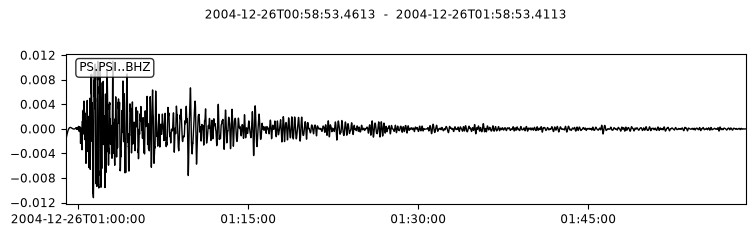

In [18]:
inv_respa = client.get_stations(
    network="PS", station="PSI", channel="BHZ", location="",
    starttime=t0a, endtime=t0a + 3600,
    level="response",
)

sta_corrected = sta.copy()
sta_corrected.remove_response(inventory=inv_respa, output="VEL")

sta_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

sta_corrected.plot();

##### M 8.4 - 122 km SW of Bengkulu, Indonesia

In [19]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

event2 = client_events.get_events(
    starttime=UTCDateTime("2007-09-11"),
    endtime=UTCDateTime("2007-09-13"),
    minmagnitude=8.3,
    maxmagnitude=8.5,
)
print(event2)

1 Event(s) in Catalog:
2007-09-12T11:10:26.830000Z |  -4.438, +101.367 | 8.4  mww | manual


In [20]:
eventb = event2[0]
originb = eventb.preferred_origin() or eventb.origins[0]
magnitudeb = eventb.preferred_magnitude() or eventb.magnitudes[0]

print(f"{originb.time}  M{magnitudeb.mag:.1f}  "
      f"lat={originb.latitude:.2f}, lon={originb.longitude:.2f}, depth={originb.depth/1000:.1f} km")

2007-09-12T11:10:26.830000Z  M8.4  lat=-4.44, lon=101.37, depth=34.0 km


In [21]:
t0b = originb.time
stb = client.get_waveforms(
    network="PS", station="PSI", location="", channel="BHZ",
    starttime=t0b, endtime=t0b + 3600,
)

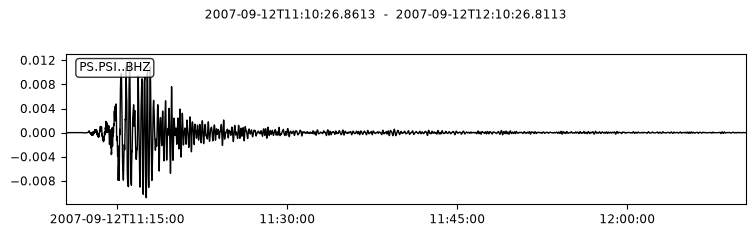

In [22]:
inv_respb = client.get_stations(
    network="PS", station="PSI", channel="BHZ", location="",
    starttime=t0b, endtime=t0b + 3600,
    level="response",
)

stb_corrected = stb.copy()
stb_corrected.remove_response(inventory=inv_respb, output="VEL")

stb_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

stb_corrected.plot();

##### M 8.6 - 78 km WSW of Singkil, Indonesia

In [23]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

event3 = client_events.get_events(
    starttime=UTCDateTime("2005-03-27"),
    endtime=UTCDateTime("2005-03-29"),
    minmagnitude=8.5,
    maxmagnitude=8.7,
)
print(event3)

1 Event(s) in Catalog:
2005-03-28T16:09:36.530000Z |  +2.085,  +97.108 | 8.6  mww | manual


In [24]:
eventc = event3[0]
originc = eventc.preferred_origin() or eventc.origins[0]
magnitudec = eventc.preferred_magnitude() or eventc.magnitudes[0]

print(f"{originc.time}  M{magnitudec.mag:.1f}  "
      f"lat={originc.latitude:.2f}, lon={originc.longitude:.2f}, depth={originc.depth/1000:.1f} km")

2005-03-28T16:09:36.530000Z  M8.6  lat=2.08, lon=97.11, depth=30.0 km


In [25]:
t0c = originc.time
stc = client.get_waveforms(
    network="PS", station="PSI", location="", channel="BHZ",
    starttime=t0c, endtime=t0c + 3600,
)

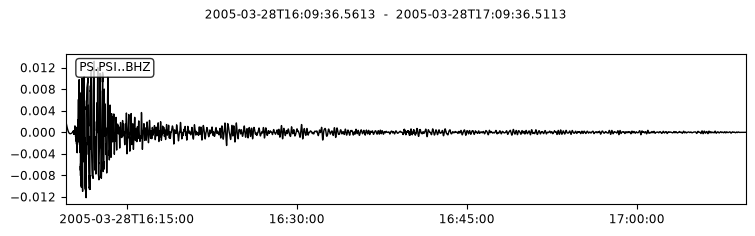

In [26]:
inv_respc = client.get_stations(
    network="PS", station="PSI", channel="BHZ", location="",
    starttime=t0c, endtime=t0c + 3600,
    level="response",
)

stc_corrected = stc.copy()
stc_corrected.remove_response(inventory=inv_respc, output="VEL")

stc_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

stc_corrected.plot();

##### M 7.9 - 87 km SW of Sungai Penuh, Indonesia

In [27]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

event4 = client_events.get_events(
    starttime=UTCDateTime("2007-09-11"),
    endtime=UTCDateTime("2007-09-13"),
    minmagnitude=7.8,
    maxmagnitude=8.0,
)
print(event4)

1 Event(s) in Catalog:
2007-09-12T23:49:03.720000Z |  -2.625, +100.841 | 7.9  mwc | manual


In [28]:
eventd = event4[0]
origind = eventd.preferred_origin() or eventd.origins[0]
magnituded = eventd.preferred_magnitude() or eventd.magnitudes[0]

print(f"{origind.time}  M{magnituded.mag:.1f}  "
      f"lat={origind.latitude:.2f}, lon={origind.longitude:.2f}, depth={origind.depth/1000:.1f} km")

2007-09-12T23:49:03.720000Z  M7.9  lat=-2.62, lon=100.84, depth=35.0 km


In [29]:
t0d = origind.time
std = client.get_waveforms(
    network="PS", station="PSI", location="", channel="BHZ",
    starttime=t0d, endtime=t0d + 3600,
)

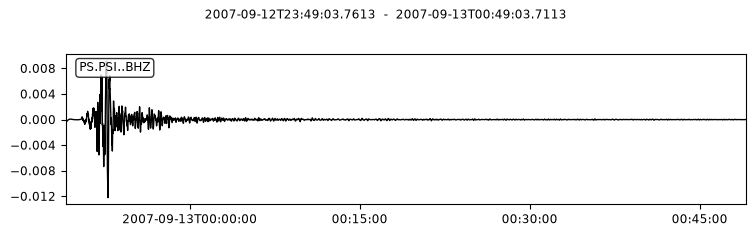

In [30]:
inv_respd = client.get_stations(
    network="PS", station="PSI", channel="BHZ", location="",
    starttime=t0d, endtime=t0d + 3600,
    level="response",
)

std_corrected = std.copy()
std_corrected.remove_response(inventory=inv_respd, output="VEL")

std_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

std_corrected.plot();

##### Apparent differences between seismograms:
##### The first seismogram, for a 9.1 magnitude earthquake, has a very noisy, sustained signal. There is a lack of space between each wave, making the whole signal almost solid black. Moving on to the next seismogram for an earthquake of magnitude 8.4, the signal starts later than the other earthquakes and has two distinct intervals of high amplitude. The third seismogram, for an earthquake of magnitude 8.6, has a tighter signal than the previous two earthquakes, and exhibits much the same noisiness as the first seismogram. The fourth seismogram, done for a magnitude 7.9 earthquake, has the weakest signal of the group, but still has a fairly large amplitude peak.

##### Average P-wave velocities:

###### M 9.1 - 2004 Sumatra - Andaman Islands Earthquake

In [31]:
pip install geopy
from geopy.distance import geodesic

coords_st = (2.69, 98.92) # PS.PSI
coords_a = (3.29, 95.98) # Earthquake Epicenter

distance_in_kma = geodesic(coords_st, coords_a).km

print(f"Distance: {distance_in_kma:.2f} km")

mambajs 0.21.4

Process pip requirements ...

Distance: 333.50 km


In [32]:
from datetime import datetime

toa = datetime(2004, 12, 26, 00, 58, 53, microsecond = 450000)
t1a = datetime(2004, 12, 26, 00, 59, 23)

dta = t1a - toa
print(dta)

0:00:29.550000


In [33]:
# P-wave velocity
pva = distance_in_kma / 29.55

print(f"P-wave velocity: {pva:.2f} km/s")

P-wave velocity: 11.29 km/s


###### M 8.4 - 122 km SW of Bengkulu, Indonesia

In [34]:
coords_b = (-4.44, 101.37)

distance_in_kmb = geodesic(coords_st, coords_b).km

print(f"Distance: {distance_in_kmb:.2f} km")

Distance: 834.18 km


In [35]:
tob = datetime(2007, 9, 12, 11, 10, 26, microsecond = 830000)
t1b = datetime(2007, 9, 12, 11, 12, 26)

dtb = t1b - tob
print(dtb)

0:01:59.170000


In [36]:
# P-wave velocity
pvb = distance_in_kmb / 119.17

print(f"P-wave velocity: {pvb:.2f} km/s")

P-wave velocity: 7.00 km/s


###### M 8.6 - 78 km WSW of Singkil, Indonesia

In [37]:
coords_c = (2.08, 97.11)

distance_in_kmc = geodesic(coords_st, coords_c).km

print(f"Distance: {distance_in_kmc:.2f} km")

Distance: 212.31 km


In [38]:
toc = datetime(2005, 3, 28, 16, 9, 36, microsecond = 530000)
t1c = datetime(2005, 3, 28, 16, 9, 56)

dtc = t1c - toc
print(dtc)

0:00:19.470000


In [39]:
# P-wave velocity
pvc = distance_in_kmc / 19.47

print(f"P-wave velocity: {pvc:.2f} km/s")

P-wave velocity: 10.90 km/s


###### M 7.9 - 87 km SW of Sungai Penuh, Indonesia

In [40]:
coords_d = (-2.62, 100.84)

distance_in_kmd = geodesic(coords_st, coords_d).km

print(f"Distance: {distance_in_kmd:.2f} km")

Distance: 624.82 km


In [41]:
tod = datetime(2007, 9, 12, 23, 49, 3, microsecond = 720000)
t1d = datetime(2007, 9, 12, 23, 50, 33)

dtd = t1d - tod
print(dtd)

0:01:29.280000


In [42]:
# P-wave velocity
pvd = distance_in_kmd / 89.28

print(f"P-wave velocity: {pvd:.2f} km/s")

P-wave velocity: 7.00 km/s


###### Overall average P-wave velocity:

In [43]:
avgp = (11.29 + 7.00 + 10.90 + 7.00) / 4
print(f"Overall average P-wave velocity: {avgp:.2f} km/s")

Overall average P-wave velocity: 9.05 km/s


##### Power Spectral Densities:

###### M 9.1 - 2004 Sumatra - Andaman Islands Earthquake

In [44]:
tra = sta[0]
dataa = tra.data
timea = tra.times()
print(tra.stats)

               network: PS
               station: PSI
              location: 
               channel: BHZ
             starttime: 2004-12-26T00:58:53.461300Z
               endtime: 2004-12-26T01:58:53.411300Z
         sampling_rate: 20.0
                 delta: 0.05
                  npts: 72000
                 calib: 1.0
_fdsnws_dataselect_url: https://service.earthscope.org/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'M', 'number_of_records': 49, 'encoding': 'STEIM2', 'byteorder': '>', 'record_length': 4096, 'filesize': 200704})
            processing: ['ObsPy 1.5.1: trim(endtime=UTCDateTime(2004, 12, 26, 1, 58, 53, 461300)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2004, 12, 26, 0, 58, 53, 461300))']


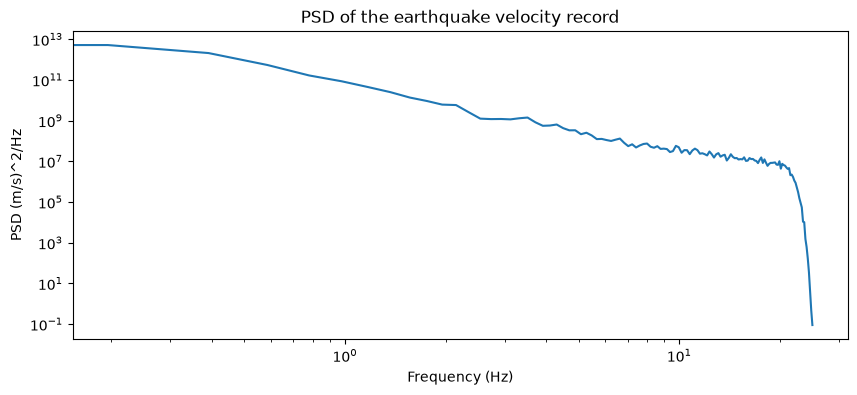

In [45]:
from scipy import signal

fE, PE = signal.welch(dataa, 50, window='hann')

plt.loglog(fE, PE)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (m/s)^2/Hz")
plt.title("PSD of the earthquake velocity record")
plt.show()

###### M 8.4 - 122 km SW of Bengkulu, Indonesia

In [46]:
trb = stb[0]
datab = trb.data
timeb = trb.times()
print(trb.stats)

               network: PS
               station: PSI
              location: 
               channel: BHZ
             starttime: 2007-09-12T11:10:26.861300Z
               endtime: 2007-09-12T12:10:26.811300Z
         sampling_rate: 20.0
                 delta: 0.05
                  npts: 72000
                 calib: 1.0
_fdsnws_dataselect_url: https://service.earthscope.org/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'M', 'number_of_records': 449, 'encoding': 'STEIM2', 'byteorder': '>', 'record_length': 512, 'filesize': 229888})
            processing: ['ObsPy 1.5.1: trim(endtime=UTCDateTime(2007, 9, 12, 12, 10, 26, 811300)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2007, 9, 12, 11, 10, 26, 811300))']


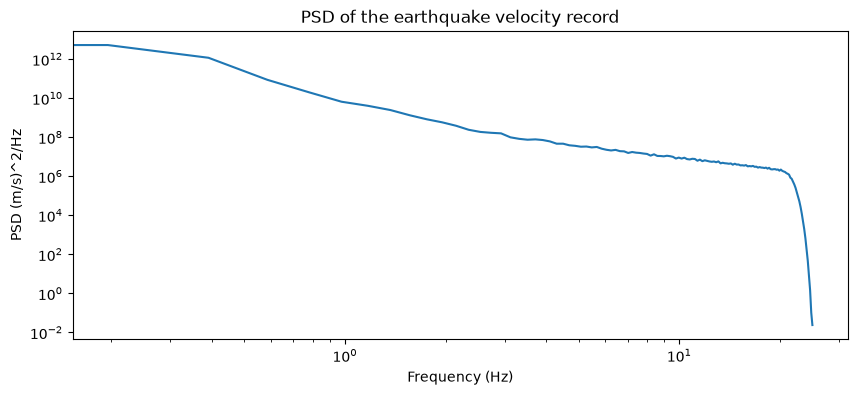

In [47]:
fE, PE = signal.welch(datab, 50, window='hann')

plt.loglog(fE, PE)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (m/s)^2/Hz")
plt.title("PSD of the earthquake velocity record")
plt.show()

###### M 8.6 - 78 km WSW of Singkil, Indonesia

In [48]:
trc = stc[0]
datac = trc.data
timec = trc.times()
print(trc.stats)

               network: PS
               station: PSI
              location: 
               channel: BHZ
             starttime: 2005-03-28T16:09:36.561300Z
               endtime: 2005-03-28T17:09:36.511300Z
         sampling_rate: 20.0
                 delta: 0.05
                  npts: 72000
                 calib: 1.0
_fdsnws_dataselect_url: https://service.earthscope.org/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'M', 'number_of_records': 47, 'encoding': 'STEIM2', 'byteorder': '>', 'record_length': 4096, 'filesize': 192512})
            processing: ['ObsPy 1.5.1: trim(endtime=UTCDateTime(2005, 3, 28, 17, 9, 36, 511300)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2005, 3, 28, 16, 9, 36, 511300))']


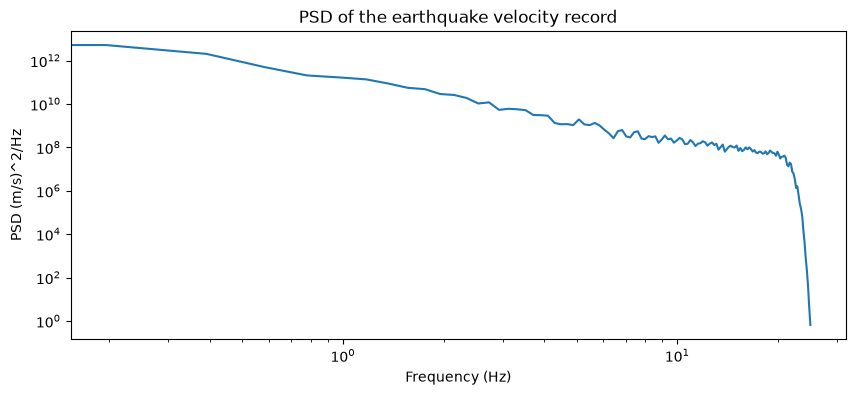

In [49]:
fE, PE = signal.welch(datac, 50, window='hann')

plt.loglog(fE, PE)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (m/s)^2/Hz")
plt.title("PSD of the earthquake velocity record")
plt.show()

###### M 7.9 - 87 km SW of Sungai Penuh, Indonesia

In [50]:
trd = std[0]
datad = trd.data
timed = trd.times()
print(trd.stats)

               network: PS
               station: PSI
              location: 
               channel: BHZ
             starttime: 2007-09-12T23:49:03.761300Z
               endtime: 2007-09-13T00:49:03.711300Z
         sampling_rate: 20.0
                 delta: 0.05
                  npts: 72000
                 calib: 1.0
_fdsnws_dataselect_url: https://service.earthscope.org/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'M', 'number_of_records': 395, 'encoding': 'STEIM2', 'byteorder': '>', 'record_length': 512, 'filesize': 202240})
            processing: ['ObsPy 1.5.1: trim(endtime=UTCDateTime(2007, 9, 13, 0, 49, 3, 711300)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2007, 9, 12, 23, 49, 3, 711300))']


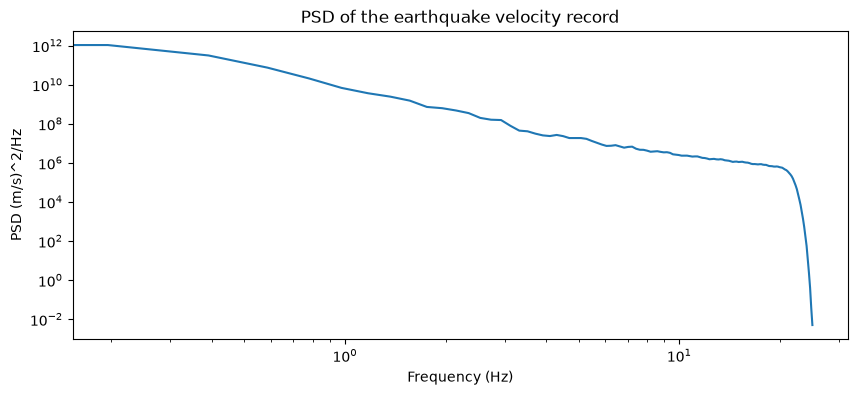

In [51]:
fE, PE = signal.welch(datad, 50, window='hann')

plt.loglog(fE, PE)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (m/s)^2/Hz")
plt.title("PSD of the earthquake velocity record")
plt.show()

##### Apparent differences between PSDs:
##### For each earthquake represented by a PSD, the velocity record is dominated by lower frequency, or longer period, ground motion, with progressively less power at higher frequencies. The curves vary by maximum power spectral density and their smoothness, with the first earthquake (M 9.1) having the highest PSD at almost 10^13 and the third earthquake (M 8.6) having the most variations in frequency (most bumpy curve). Each curve also has a sharp dropoff in PSD near the end of the curve, meaning that there is a lack of high frequency ground motion. In general, the fourth earthquake (M 7.9) has the most linear curve, with the least linear curve being the second earthquake (M 8.4). A more linear curve means that the PSD is decreasing with frequency on a more or less consistent power law slope.

### Question 3b

#### For one of the Sumatra earthquakes, find vertical component velocity seismograms for 4 different stations at different source distances and plot them as a function of distance from the source in degrees. Make an estimate of the average velocity here based on the P wave arrivals.

In [52]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

event1 = client_events.get_events(
    starttime=UTCDateTime("2004-12-25"),
    endtime=UTCDateTime("2004-12-27"),
    minmagnitude=9.0,
    maxmagnitude=9.2,
)
print(event1)

eventa = event1[0]
origina = eventa.preferred_origin() or eventa.origins[0]
magnitudea = eventa.preferred_magnitude() or eventa.magnitudes[0]

print(f"{origina.time}  M{magnitudea.mag:.1f}  "
      f"lat={origina.latitude:.2f}, lon={origina.longitude:.2f}, depth={origina.depth/1000:.1f} km")

1 Event(s) in Catalog:
2004-12-26T00:58:53.450000Z |  +3.295,  +95.982 | 9.1  mw | manual
2004-12-26T00:58:53.450000Z  M9.1  lat=3.29, lon=95.98, depth=30.0 km


In [53]:
client = Client("https://service.earthscope.org", _discover_services=False)

In [54]:
inventory = client.get_stations(
    starttime=origina.time,
    endtime=origina.time + 3600,
    latitude=origina.latitude,
    longitude=origina.longitude,
    minradius=10,
    maxradius=90,
    channel="BHZ",
    level="channel"
)

print(inventory)

Inventory created at 2026-09-21T14:27:27.511600Z
	Created by: EarthScope WEB SERVICE: fdsnws-station | version: 1.1.57
		    https://service.earthscope.org/fdsnws/station/1/query?starttime=200...
	Sending institution: EarthScope (EarthScope)
	Contains:
		Networks (40):
			AF, AK, AT, AU, CB, CH, CZ, DK, ER, G, GE, GR, GT, HL, IC, II, IM, 
			IU, JP, KG, KN, KO, KZ, MI, MN, NL, NO, OE, PL, PS, RO, SL, TW, XE
			XF, XG, XO, YA, YD, YI
		Stations (692):
			AF.WIN (Windhoek, Namibia)
			AK.ATKA (Atka Island, AK, USA)
			AK.GAMB (Gambell, AK, USA)
			AK.SPIA (St Paul Island, AK, USA)
			AK.TNA (Tin City, AK, USA)
			AT.SMY (Shemya, Alaska)
			AU.BBOO (Buckleboo, South Australia)
			AU.BLDU (Ballidu, Western Australia)
			AU.COEN (Coen, Queensland)
			AU.EIDS (Eidsvold, QLD)
			AU.FITZ (Fitzroy Crossing)
			AU.FORT (Forrest, WA)
			AU.KMBL (Kambalda, WA)
			AU.MAW (Mawson, Antarctica)
			AU.MCQ (Macquarie Island)
			AU.MUN (Mundaring, Western Australia)
			AU.NWAO (Narrogin, Western Australi

In [55]:
from obspy.geodetics import locations2degrees

stations = [("TW", "TWKB"), ("TW", "NACB"), ("II", "WRAB"), ("IM", "ATTU")]

for network, station in stations:

    inv = client.get_stations(
        network=network,
        station=station,
        channel="BHZ",
        starttime=origina.time,
        endtime=origina.time + 3600,
        level="station"
    )

    sta = inv[0][0]

    distance = locations2degrees(
        origina.latitude,
        origina.longitude,
        sta.latitude,
        sta.longitude
    )

    print(
        network,
        station,
        "lat =", sta.latitude,
        "lon =", sta.longitude,
        "distance =", round(distance, 2), "degrees"
    )

TW TWKB lat = 21.940901 lon = 120.8125 distance = 30.47 degrees
TW NACB lat = 24.1738 lon = 121.594704 distance = 32.35 degrees
II WRAB lat = -19.9335 lon = 134.3594 distance = 44.26 degrees
IM ATTU lat = 52.882099 lon = 173.164307 distance = 79.66 degrees


##### TW.TWKB

In [56]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

t01 = origina.time
st1 = client.get_waveforms(
    network="TW", station="TWKB", location="", channel="BHZ",
    starttime=t01, endtime=t01 + 3600,
)

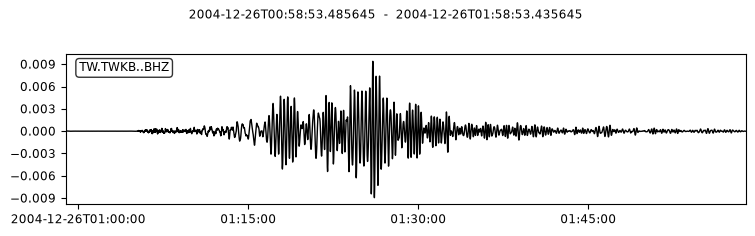

In [57]:
inv_resp1 = client.get_stations(
    network="TW", station="TWKB", channel="BHZ", location="",
    starttime=t01, endtime=t01 + 3600,
    level="response",
)

st1_corrected = st1.copy()
st1_corrected.remove_response(inventory=inv_resp1, output="VEL")

st1_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st1_corrected.plot();

##### TW.NACB

In [58]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

t02 = origina.time
st2 = client.get_waveforms(
    network="TW", station="NACB", location="", channel="BHZ",
    starttime=t02, endtime=t02 + 3600,
)

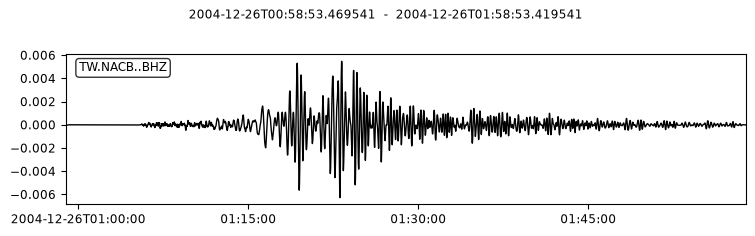

In [59]:
inv_resp2 = client.get_stations(
    network="TW", station="NACB", channel="BHZ", location="",
    starttime=t02, endtime=t02 + 3600,
    level="response",
)

st2_corrected = st2.copy()
st2_corrected.remove_response(inventory=inv_resp2, output="VEL")

st2_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st2_corrected.plot();

##### II.WRAB

In [60]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

t03 = origina.time
st3 = client.get_waveforms(
    network="II", station="WRAB", location="00", channel="BHZ",
    starttime=t03, endtime=t03 + 3600,
)

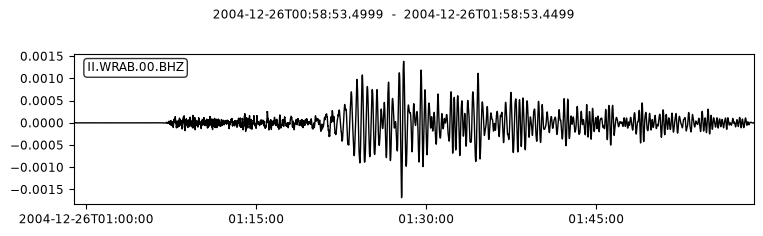

In [61]:
inv_resp3 = client.get_stations(
    network="II", station="WRAB", channel="BHZ", location="00",
    starttime=t03, endtime=t03 + 3600,
    level="response",
)

st3_corrected = st3.copy()
st3_corrected.remove_response(inventory=inv_resp3, output="VEL")

st3_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st3_corrected.plot();

##### IM.ATTU

In [62]:
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

t04 = origina.time
st4 = client.get_waveforms(
    network="IM", station="ATTU", location="", channel="BHZ",
    starttime=t04, endtime=t04 + 3600,
)

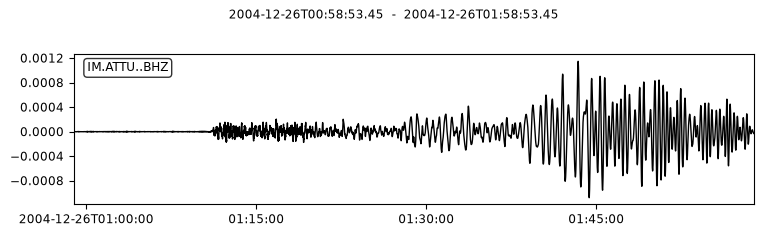

In [63]:
inv_resp4 = client.get_stations(
    network="IM", station="ATTU", channel="BHZ", location="",
    starttime=t04, endtime=t04 + 3600,
    level="response",
)

st4_corrected = st4.copy()
st4_corrected.remove_response(inventory=inv_resp4, output="VEL")

st4_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st4_corrected.plot();

In [64]:
stations = [
    ("TW", "TWKB"),
    ("TW", "NACB"),
    ("II", "WRAB"),
    ("IM", "ATTU")
]

traces = {}

for network, station in stations:

    st = client.get_waveforms(
        network=network,
        station=station,
        location="*",
        channel="BHZ",
        starttime=t01,
        endtime=t01 + 3600
    )
    inv = client.get_stations(
        network=network,
        station=station,
        location="*",
        channel="BHZ",
        starttime=t01,
        endtime=t01 + 3600,
        level="response"
    )
    st.remove_response(
        inventory=inv,
        output="VEL"
    )
    st.filter(
        "bandpass",
        freqmin=0.02,
        freqmax=9.99,
        corners=4,
        zerophase=True
    )

    traces[station] = st[0]

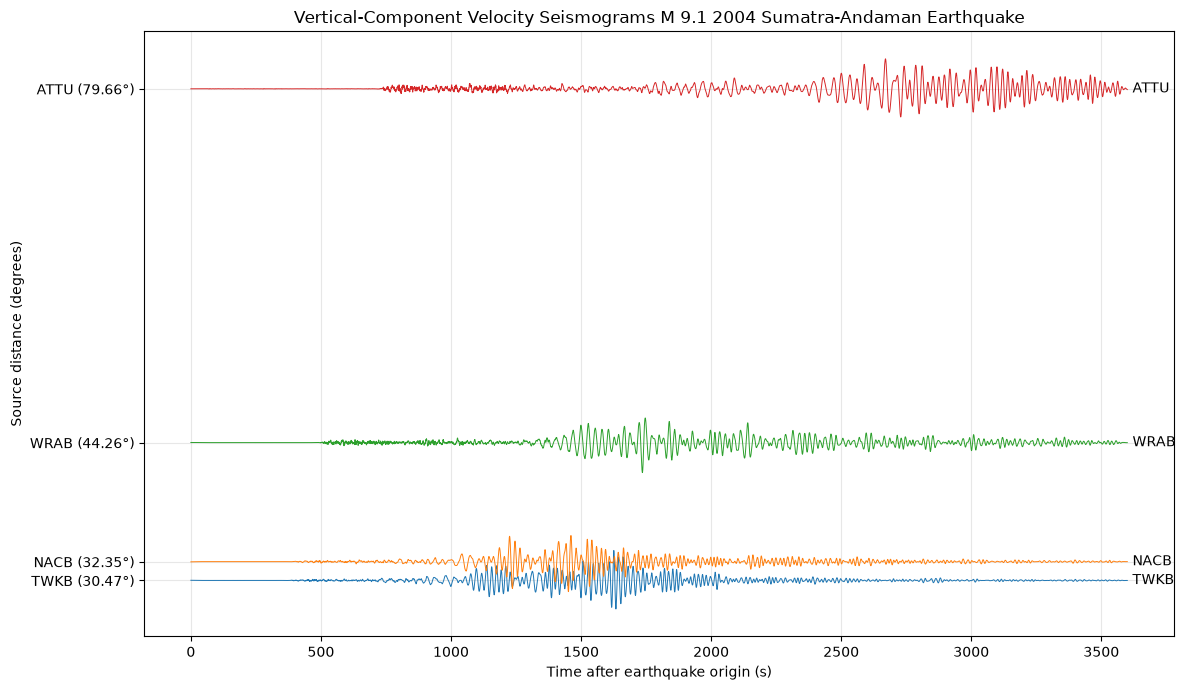

In [65]:
import numpy as np
import matplotlib.pyplot as plt

distances = {
    "TWKB": 30.47,
    "NACB": 32.35,
    "WRAB": 44.26,
    "ATTU": 79.66
}

stations = ["TWKB", "NACB", "WRAB", "ATTU"]

fig, ax = plt.subplots(figsize=(12, 7))

for station in stations:
    tr = traces[station]
    time = tr.times()
    data = tr.data.astype(float)
    data = data / np.max(np.abs(data))
    amplitude = 3.0
    ax.plot(
        time,
        distances[station] + amplitude * data,
        linewidth=0.7
    )
    ax.text(
        time[-1] + 20,
        distances[station],
        station,
        va="center"
    )

ax.set_xlabel("Time after earthquake origin (s)")
ax.set_ylabel("Source distance (degrees)")
ax.set_title("Vertical-Component Velocity Seismograms M 9.1 2004 Sumatra-Andaman Earthquake")

ax.set_yticks([distances[s] for s in stations])
ax.set_yticklabels([f"{s} ({distances[s]:.2f}°)" for s in stations])

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### Average P-wave velocities:

###### Distances in km:

In [66]:
# One degree of great-circle distance is approximately 111.2 km
TWKB_dist = 30.47 * 111.2
NACB_dist = 32.35 * 111.2
WRAB_dist = 44.26 * 111.2
ATTU_dist = 79.66 * 111.2

###### Time in seconds:

In [67]:
# TWKB
to1 = datetime(2004, 12, 26, 00, 58, 53, microsecond = 450000)
t11 = datetime(2004, 12, 26, 1, 5, 23)
TWKB_t = t11 - to1
print(TWKB_t)

to2 = datetime(2004, 12, 26, 00, 58, 53, microsecond = 450000)
t12 = datetime(2004, 12, 26, 1, 5, 53)
NACB_t = t12 - to2
print(NACB_t)

to3 = datetime(2004, 12, 26, 00, 58, 53, microsecond = 450000)
t13 = datetime(2004, 12, 26, 1, 7, 23)
WRAB_t = t13 - to3
print(WRAB_t)

to4 = datetime(2004, 12, 26, 00, 58, 53, microsecond = 450000)
t14 = datetime(2004, 12, 26, 1, 12, 23)
ATTU_t = t14 - to4
print(ATTU_t)

0:06:29.550000
0:06:59.550000
0:08:29.550000
0:13:29.550000


###### P-wave velocities:

In [68]:
TWKB_v = TWKB_dist / 389.55
print(f"TWKB P-wave velocity: {TWKB_v:.2f} km/s")

NACB_v = NACB_dist / 419.55
print(f"NACB P-wave velocity: {NACB_v:.2f} km/s")

WRAB_v = WRAB_dist / 509.55
print(f"WRAB P-wave velocity: {WRAB_v:.2f} km/s")

ATTU_v = ATTU_dist / 809.55
print(f"ATTU P-wave velocity: {ATTU_v:.2f} km/s")

pavg1 = (TWKB_v + NACB_v + WRAB_v + ATTU_v) / 4
print(f"Overall average P-wave velocity: {pavg1:.2f} km/s")

TWKB P-wave velocity: 8.70 km/s
NACB P-wave velocity: 8.57 km/s
WRAB P-wave velocity: 9.66 km/s
ATTU P-wave velocity: 10.94 km/s
Overall average P-wave velocity: 9.47 km/s


### Question 3c

#### For one of your waveforms, apply a high-pass filter at 0.01 and 1 Hz and plot the results. Label any phase arrivals that you may see.

##### High-pass filter at 0.01 Hz:

In [69]:
import matplotlib.pyplot as plt

st_001 = st1_corrected.copy()

st_001.filter("highpass", freq=0.01, corners=4, zerophase=True)

1 Trace(s) in Stream:
TW.TWKB..BHZ | 2004-12-26T00:58:53.485645Z - 2004-12-26T01:58:53.435645Z | 20.0 Hz, 72000 samples

##### High-pass filter at 1 Hz:

In [70]:
st_1 = st1_corrected.copy()

st_1.filter("highpass", freq=1.0, corners=4, zerophase=True)

1 Trace(s) in Stream:
TW.TWKB..BHZ | 2004-12-26T00:58:53.485645Z - 2004-12-26T01:58:53.435645Z | 20.0 Hz, 72000 samples

##### Plot:

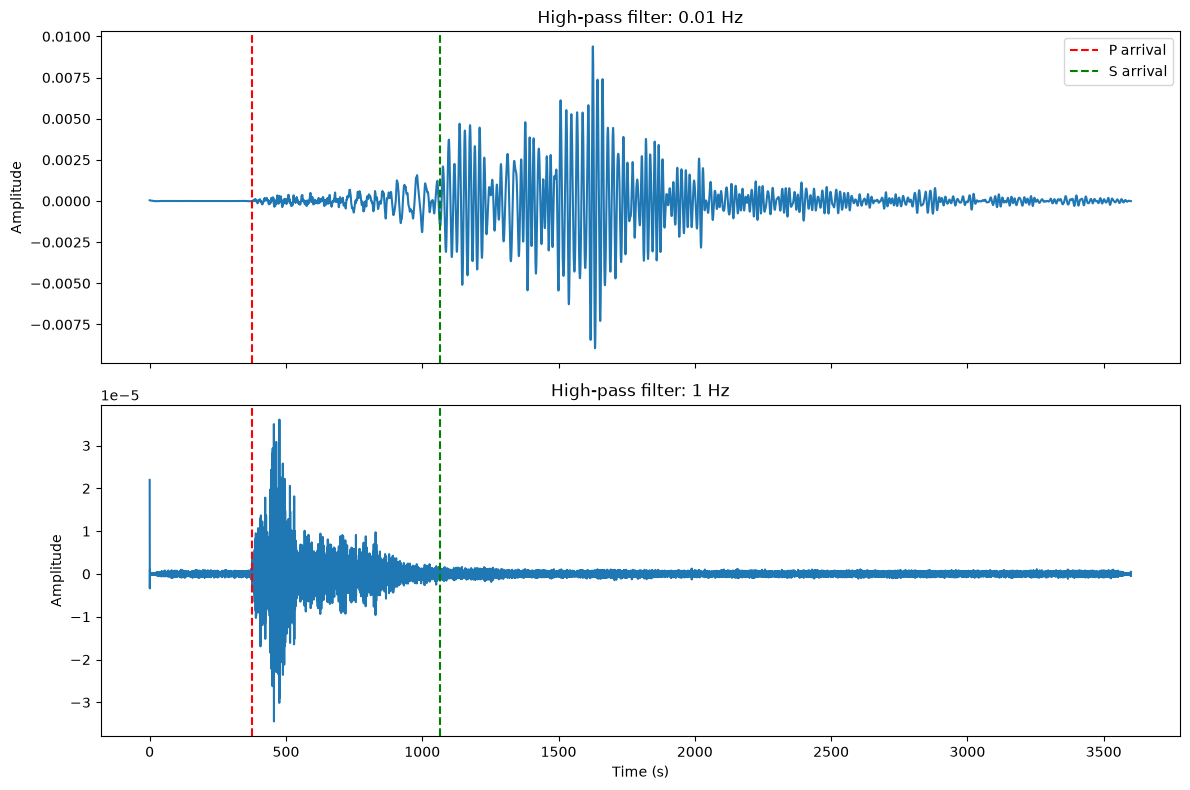

In [71]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(st_001[0].times(), st_001[0].data)
axes[0].set_title("High-pass filter: 0.01 Hz")
axes[0].set_ylabel("Amplitude")

axes[1].plot(st_1[0].times(), st_1[0].data)
axes[1].set_title("High-pass filter: 1 Hz")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")

p_arrival = 375
s_arrival = 1065

for ax in axes:
    ax.axvline(p_arrival, linestyle="--", label="P arrival", color = "red")
    ax.axvline(s_arrival, linestyle="--", label="S arrival", color = "green")

axes[0].legend()

plt.tight_layout()
plt.show()

## All done!